In [1]:
from dotenv import load_dotenv
from typing_extensions import TypedDict, Annotated
import operator
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.prebuilt import ToolNode
import os
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI
load_dotenv()
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)



In [2]:
class ChatState(TypedDict):
    messages: Annotated[list, add_messages]

In [3]:
def chat_node(state: ChatState):
    reply = llm.invoke(state["messages"])
    return {"messages": [reply]}

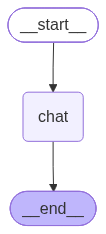

In [4]:
builder = StateGraph(ChatState)
builder.add_node("chat", chat_node)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)
graph = builder.compile()
graph

In [5]:
graph.invoke({"messages": [HumanMessage(content="Hi, I am Rahul.")]})


{'messages': [HumanMessage(content='Hi, I am Rahul.', additional_kwargs={}, response_metadata={}, id='f55f44a9-376b-4fc2-82e5-73d0b1c3d562'),
  AIMessage(content='Hi Rahul! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_c5012d6921', 'id': 'chatcmpl-Egjee4aIWDCJuhY8ypC6PIgpUui1M', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1aa07-7a27-701e-b0eb-41e3e9f085a7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_

In [6]:
graph.invoke({"messages": [HumanMessage(content="what is my name.")]})


{'messages': [HumanMessage(content='what is my name.', additional_kwargs={}, response_metadata={}, id='036b78c3-2ddb-40fd-b782-a533d44895dc'),
  AIMessage(content="I'm sorry, but I don't have access to personal information about individuals unless it has been shared with me in the course of our conversation. If you'd like to tell me your name, feel free!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 12, 'total_tokens': 51, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_73c5e31c8b', 'id': 'chatcmpl-EgjehjsWI93BkZ31beW20NEmqsCgj', 'service_tier': 'default', 'finish_reason': 'stop'

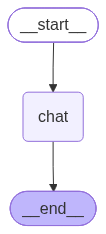

In [7]:
#addding memory to the graph
builder = StateGraph(ChatState)
builder.add_node("chat", chat_node)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)

memory = MemorySaver()
agent = builder.compile(checkpointer=memory)
agent


In [8]:
config_1 = {"configurable": {"thread_id": "chat-1"}}

In [9]:
agent.invoke({"messages": [HumanMessage(content="Hi, I am Rahul.")]}, config_1)


{'messages': [HumanMessage(content='Hi, I am Rahul.', additional_kwargs={}, response_metadata={}, id='54b1dff9-4878-4320-9209-95ec6d0f9307'),
  AIMessage(content='Hi Rahul! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_c5012d6921', 'id': 'chatcmpl-EgjfQoxyY6jXozmtHDR5WyaGkRwkQ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1aa08-3afe-72ea-8feb-fbdc52936405-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_

In [10]:
agent.invoke({"messages": [HumanMessage(content="who I am ")]}, config_1)


{'messages': [HumanMessage(content='Hi, I am Rahul.', additional_kwargs={}, response_metadata={}, id='54b1dff9-4878-4320-9209-95ec6d0f9307'),
  AIMessage(content='Hi Rahul! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_c5012d6921', 'id': 'chatcmpl-EgjfQoxyY6jXozmtHDR5WyaGkRwkQ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1aa08-3afe-72ea-8feb-fbdc52936405-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_

In [11]:
agent.invoke({"messages": [HumanMessage(content="suggest some good name for me ")]}, config_1)


{'messages': [HumanMessage(content='Hi, I am Rahul.', additional_kwargs={}, response_metadata={}, id='54b1dff9-4878-4320-9209-95ec6d0f9307'),
  AIMessage(content='Hi Rahul! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_c5012d6921', 'id': 'chatcmpl-EgjfQoxyY6jXozmtHDR5WyaGkRwkQ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1aa08-3afe-72ea-8feb-fbdc52936405-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_

In [15]:
config_1_chat1={"configurable": {"thread_id": "chat-1"}}

In [16]:
agent.invoke({"messages": [HumanMessage(content="who I am ")]}, config_1_chat1)

{'messages': [HumanMessage(content='Hi, I am Rahul.', additional_kwargs={}, response_metadata={}, id='54b1dff9-4878-4320-9209-95ec6d0f9307'),
  AIMessage(content='Hi Rahul! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_c5012d6921', 'id': 'chatcmpl-EgjfQoxyY6jXozmtHDR5WyaGkRwkQ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1aa08-3afe-72ea-8feb-fbdc52936405-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_

In [17]:
config_2={"configurable": {"thread_id": "chat-2"}}

agent.invoke({"messages": [HumanMessage(content="who I am ")]}, config_2)

{'messages': [HumanMessage(content='who I am ', additional_kwargs={}, response_metadata={}, id='9a23a28c-2a0b-462d-afc6-20c55b2c784a'),
  AIMessage(content="I don't have access to personal data about individuals unless it has been shared with me in the course of our conversation. If you'd like to share more about yourself or ask specific questions, feel free to do so!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 42, 'prompt_tokens': 11, 'total_tokens': 53, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_848297e121', 'id': 'chatcmpl-EgjiGsI7mRIyTk3OHXGM6fK6GH6Ar', 'service_tier': 'default', 'finish_r

In [ ]:
#questions
1. what is the role config and thread_id playing